# Physical AI 講座 2026 応用編1 第6回 Hands-on
## dora-rs 入門：dataflow を書いて、動かして、いじってみる（想定約10分・Google Colab）

**上から順に Shift+Enter を押すだけ** で動きます。GPU 不要・実機不要。

| Step | 内容 | 目安 |
|---|---|---|
| 0 | dora のインストール | 1分 |
| 1 | 最小の dataflow：タイマー → 2倍 → 表示 | 2分 |
| 2 | センサー → フィルタ → モニタ：NumPy 配列を流す・パラメータを渡す・複数入力を受ける | 3分 |
| 3 | 配線だけ変える：記録ノードを足して、raw と smoothed をプロット | 3分 |
| 宿題 | しきい値で alarm を出すノードを追加する | — |

参考: [dora-rs/dora](https://github.com/dora-rs/dora) ・ [Python guide](https://github.com/dora-rs/dora/blob/main/docs/python-guide.md)


## Step 0. インストール

dora のインストールは `pip install dora-rs-cli` の1行です（CLI + Python API `dora`）。

In [17]:
!pip -q install "dora-rs-cli==1.0.1" "dora-rs==1.0.1" pyarrow numpy pandas matplotlib
import os
os.makedirs("/content/dora_handson", exist_ok=True)
%cd /content/dora_handson
!dora --version

/content/dora_handson
dora-cli 1.0.1


## Step 1. 最小の dataflow：タイマー → 2倍 → 表示

dora のシンプルな構成は **dataflow.yml（どことどこをどう繋げるか）＋ ノード（ただの Python スクリプト）** だけです。

- `nodes:` の 1 ブロック = 1 ノード = 1 プロセス
- `inputs:` は「入力名: 送り元ノード/出力名」。`dora/timer/millis/500` は dora 組込みのタイマー（500ms ごとにイベント）
- ノードは `Node()` でイベントを受け取り、`send_output()` で次のノードへ流す。データは **Apache Arrow 配列**

In [18]:
%%writefile dataflow.yml
nodes:
  - id: doubler
    path: doubler.py
    inputs:
      tick: dora/timer/millis/500      # 500ms ごとに tick が届く
    outputs: [doubled]

  - id: printer
    path: printer.py
    inputs:
      message: doubler/doubled         # 「送り元ノード/出力名」で配線

Overwriting dataflow.yml


In [25]:
%%writefile doubler.py
import pyarrow as pa
from dora import Node

node = Node()
count = 0
for event in node:                      # event["type"]: INPUT / INPUT_CLOSED / STOP / ERROR
    if event["type"] == "INPUT":
        count += 1
        node.send_output("doubled", pa.array([count * 2]))   # Arrow 配列で送る
        if count >= 5:                  # 5回送ったら終了（全ノードが終わると dora run も終わる）
            break
    elif event["type"] == "STOP":
        break

Overwriting doubler.py


In [26]:
%%writefile printer.py
from dora import Node

node = Node()
for event in node:
    if event["type"] == "INPUT":
        print("received:", event["value"].to_pylist(), flush=True)
    elif event["type"] in ("STOP", "INPUT_CLOSED"):   # 送り元が終了したら自分も終了
        break

Overwriting printer.py


`dora run` は coordinator / daemon / 各ノードをまとめて起動し、全ノードが終了すると自動で終わります。
`received: [2] [4] ... [10]` と出れば成功です。

In [27]:
!dora run dataflow.yml

doubler: DEBUG    building node
printer: DEBUG    building node
06:29:07 DEBUG  doubler: daemon::spawner spawning node
06:29:07 DEBUG  printer: daemon::spawner spawning node
06:29:07 INFO   doubler: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/doubler.py
06:29:07 INFO   printer: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/printer.py

06:29:07 INFO   [dora]: dora daemon finished building nodes, spawning...

06:29:07 INFO   doubler: spawner spawning `/usr/bin/python3` in `/content/dora_handson`
06:29:07 DEBUG  doubler: spawner spawned node with pid 90052
06:29:07 INFO   printer: spawner spawning `/usr/bin/python3` in `/content/dora_handson`
06:29:07 DEBUG  printer: spawner spawned node with pid 90053
06:29:07 INFO   doubler: daemon node is ready
06:29:07 INFO   printer: daemon node is ready
06:29:07 INFO   [dora]: daemon all nodes are ready, starting dataflow
06:29:08 stdout printer: received: [5]
06:29:08 stdout printer: received: [10]
06:29:08 stdout 

> **やってみよう**: `doubler.py` の `count * 2` を `count * 3` にして、writefile と `dora run` のセルをもう一度実行。
> ノードは「ただの Python スクリプト」なので、書き換えて再実行するだけです。

## Step 2. センサー → フィルタ → モニタ

ロボットらしい形にします。3軸の（ニセ）センサー値を流し、移動平均で平滑化し、モニタが raw と smoothed の両方を受け取ります。

ここで覚えること 3 つ：

1. **NumPy 配列をそのまま流せる** — `pa.array(np_array)` で送り、`event["value"].to_numpy()` で受ける（Arrow はゼロコピーで NumPy / Polars / Torch と相互変換）
2. **パラメータは yaml の `env:` で渡す** — コードを触らず窓幅を変えられる
3. **複数入力は `event["id"]` で見分ける** — 1 ノードが何本でも入力を受けられる

In [28]:
%%writefile dataflow2.yml
nodes:
  - id: sensor
    path: sensor.py
    inputs:
      tick: dora/timer/millis/100      # 10 Hz
    outputs: [reading]

  - id: filter
    path: filter.py
    env:
      WINDOW: "5"                      # 移動平均の窓幅（ノードにパラメータを渡す）
    inputs:
      reading: sensor/reading
    outputs: [smoothed]

  - id: monitor
    path: monitor.py
    inputs:
      raw: sensor/reading              # 同じ出力を複数のノードが受け取れる（pub/sub）
      smoothed: filter/smoothed

Overwriting dataflow2.yml


In [29]:
%%writefile sensor.py
import numpy as np
import pyarrow as pa
from dora import Node

node = Node()
rng = np.random.default_rng(0)
N = 30                                   # 30 サンプル送ったら終了（3 秒）
for i, event in enumerate(node):
    if event["type"] != "INPUT":
        break
    t = i / 10
    value = np.array([np.sin(t), np.cos(t), 0.0]) + rng.normal(0, 0.2, 3)   # 3軸 + ノイズ
    node.send_output("reading", pa.array(value.astype(np.float32)), metadata={"t": t})
    if i + 1 >= N:
        break

Overwriting sensor.py


In [30]:
%%writefile filter.py
import os
from collections import deque
import numpy as np
import pyarrow as pa
from dora import Node

WINDOW = int(os.environ.get("WINDOW", "5"))   # yaml の env: から
node = Node()
buf = deque(maxlen=WINDOW)
for event in node:
    if event["type"] == "INPUT":
        buf.append(event["value"].to_numpy())          # Arrow → NumPy
        node.send_output("smoothed", pa.array(np.mean(buf, axis=0)), metadata=event["metadata"])
    elif event["type"] in ("STOP", "INPUT_CLOSED"):
        break

Overwriting filter.py


In [31]:
%%writefile monitor.py
import numpy as np
from dora import Node

node = Node()
closed = set()
for event in node:
    if event["type"] == "INPUT":
        v = event["value"].to_numpy()
        print(f"t={event['metadata']['t']:.1f}  {event['id']:8s} {np.round(v, 2)}", flush=True)
    elif event["type"] == "INPUT_CLOSED":
        closed.add(event["id"])
        if closed == {"raw", "smoothed"}:                # 2 本とも閉じたら終了
            break
    elif event["type"] == "STOP":
        break

Overwriting monitor.py


実行前に `dora graph --mermaid` で配線図を出してみます（yaml から自動生成）。

In [32]:
!dora graph dataflow2.yml --mermaid

flowchart TB
  filter["**filter**"]
  monitor[/"**monitor**"\]
  sensor["**sensor**"]
subgraph ___dora___ [dora]
  subgraph ___timer_timer___ [timer]
    dora/timer/millis/100[\millis/100/]
  end
end
  sensor -- reading --> filter
  sensor -- reading as raw --> monitor
  filter -- smoothed --> monitor
  dora/timer/millis/100 -- tick --> sensor

Paste the above output on https://mermaid.live/ or in a ```mermaid code block on GitHub to display it.


In [33]:
!dora run dataflow2.yml

filter: DEBUG    building node
monitor: DEBUG    building node
sensor: DEBUG    building node
06:31:51 DEBUG  filter: daemon::spawner spawning node
06:31:51 DEBUG  monitor: daemon::spawner spawning node
06:31:51 DEBUG  sensor: daemon::spawner spawning node
06:31:51 INFO   filter: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/filter.py
06:31:51 INFO   monitor: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/monitor.py
06:31:51 INFO   sensor: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/sensor.py

06:31:51 INFO   [dora]: dora daemon finished building nodes, spawning...

06:31:51 INFO   filter: spawner spawning `/usr/bin/python3` in `/content/dora_handson`
06:31:51 DEBUG  filter: spawner spawned node with pid 90794
06:31:51 INFO   monitor: spawner spawning `/usr/bin/python3` in `/content/dora_handson`
06:31:51 DEBUG  monitor: spawner spawned node with pid 90798
06:31:51 INFO   sensor: spawner spawning `/usr/bin/python3` in `/content/dora_hand

> **やってみよう**: `dataflow2.yml` の `WINDOW: "5"` を `"20"` にして `dora run` し直すと、smoothed が滑らかになる代わりに遅れます。

## Step 3. 記録ノードを足して可視化

sensor / filter は **そのまま** で、yaml に `recorder` を 1 ノード足すだけで raw と smoothed を CSV に残せます。
（dora には `dora record` / `dora replay` という rosbag 相当の機能もあります）

In [34]:
%%writefile recorder.py
import csv
from dora import Node

node = Node()
rows = {}                                    # t → {"raw": [...], "smoothed": [...]}
closed = set()
for event in node:
    if event["type"] == "INPUT":
        t = round(event["metadata"]["t"], 3)           # 浮動小数のキー揺れを防ぐ
        rows.setdefault(t, {})[event["id"]] = event["value"].to_pylist()
    elif event["type"] == "INPUT_CLOSED":
        closed.add(event["id"])
        if closed == {"raw", "smoothed"}:
            break
    elif event["type"] == "STOP":
        break

with open("log.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["t", "raw_x", "raw_y", "raw_z", "smooth_x", "smooth_y", "smooth_z"])
    for t in sorted(rows):
        r = rows[t]
        if "raw" in r and "smoothed" in r:
            w.writerow([t, *r["raw"], *r["smoothed"]])
print("wrote log.csv:", len(rows), "rows", flush=True)

Overwriting recorder.py


In [35]:
# dataflow2.yml に recorder を追記（sensor / filter / monitor は無変更）
extra = '''
  - id: recorder
    path: recorder.py
    inputs:
      raw: sensor/reading
      smoothed: filter/smoothed
'''
open("dataflow3.yml", "w").write(open("dataflow2.yml").read().rstrip() + "\n" + extra)
!dora graph dataflow3.yml --mermaid


flowchart TB
  filter["**filter**"]
  monitor[/"**monitor**"\]
  recorder[/"**recorder**"\]
  sensor["**sensor**"]
subgraph ___dora___ [dora]
  subgraph ___timer_timer___ [timer]
    dora/timer/millis/100[\millis/100/]
  end
end
  sensor -- reading --> filter
  sensor -- reading as raw --> monitor
  filter -- smoothed --> monitor
  sensor -- reading as raw --> recorder
  filter -- smoothed --> recorder
  dora/timer/millis/100 -- tick --> sensor

Paste the above output on https://mermaid.live/ or in a ```mermaid code block on GitHub to display it.


In [36]:
!dora run dataflow3.yml

filter: DEBUG    building node
monitor: DEBUG    building node
recorder: DEBUG    building node
sensor: DEBUG    building node
06:33:52 DEBUG  filter: daemon::spawner spawning node
06:33:52 DEBUG  monitor: daemon::spawner spawning node
06:33:52 DEBUG  recorder: daemon::spawner spawning node
06:33:52 DEBUG  sensor: daemon::spawner spawning node
06:33:52 INFO   filter: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/filter.py
06:33:52 INFO   monitor: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/monitor.py
06:33:52 INFO   recorder: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/recorder.py
06:33:52 INFO   sensor: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/sensor.py

06:33:52 INFO   [dora]: dora daemon finished building nodes, spawning...

06:33:52 INFO   filter: spawner spawning `/usr/bin/python3` in `/content/dora_handson`
06:33:52 DEBUG  filter: spawner spawned node with pid 91409
06:33:52 INFO   monitor: spawner spawning 

,t,raw_x,raw_y,raw_z,smooth_x,smooth_y,smooth_z
0,0.0,0.025146,0.973579,0.128085,0.025146,0.973579,0.128085
1,0.1,0.120813,0.887870,0.072319,0.072980,0.930725,0.100202
2,0.2,0.459469,1.169483,-0.140747,0.201810,1.010311,0.019886
3,0.3,0.042436,0.830682,0.008265,0.161966,0.965403,0.016980
4,0.4,-0.075588,0.877303,-0.249182,0.114455,0.947783,-0.036252


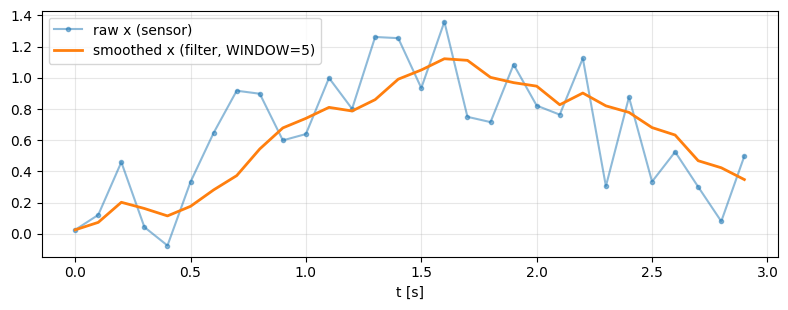

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("log.csv")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(df.t, df.raw_x, ".-", alpha=0.5, label="raw x (sensor)")
ax.plot(df.t, df.smooth_x, "-", lw=2, label="smoothed x (filter, WINDOW=5)")
ax.set_xlabel("t [s]"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("plot.png", dpi=120)
df.head()

やったことをまとめると：

- **ノード = Python スクリプト**（`Node()` → イベントループ → `send_output()`）
- **dataflow.yml = 配線とパラメータ**。ノードを足す・入れ替える・窓幅を変えるのは yaml だけ
- **データは Arrow 配列**。NumPy とゼロコピーで行き来できる（画像や関節角も同じ形で流れる）

実際のロボット（OpenArm）でも、`sensor` が「アームやカメラのドライバ」、`filter` が「IK や推論」、`recorder` が「データセット recorder」になるだけで、形はまったく同じです。

## 宿題：alarm ノードを追加する

`filter/smoothed` を受け取り、`|x| > 0.8` のときだけ `alarm` を出力するノード `alarm.py` を書き、`monitor` が `alarm` も受け取って表示するように配線してください。
（ヒント：`monitor.py` の `closed == {...}` に `"alarm"` を足すのを忘れずに）

In [ ]:
%%writefile alarm.py
import numpy as np
import pyarrow as pa
from dora import Node

THRESHOLD = 0.8
node = Node()
for event in node:
    if event["type"] == "INPUT":
        v = event["value"].to_numpy()
        # TODO: v[0] の絶対値が THRESHOLD を超えたら node.send_output("alarm", pa.array([float(v[0])]), metadata=event["metadata"])
        pass
    elif event["type"] in ("STOP", "INPUT_CLOSED"):
        break

## 発展（配布資料）
### mac/ ubunutの人向け
OpenArm 勉強会の資料. dora上に構築されたdata-collectionを動かしてみる.
https://canva.link/mlh0hr3l7478y41

OpenArm Cell で学ぶ dora-rs (MuJoCo) :起動~data collectionまで
https://note.com/duckduck1836/n/nfb1b17e7e897
### VRを持っている人むけ
OpenArm Tutorial. webxrを用いたテレオペレーション
https://docs.openarm.dev/tutorial/data-collection-webxr